In [2]:
import qiskit
import qiskit_ibm_runtime
import pylatexenc

from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit.circuit import Parameter
from qiskit.circuit.library import UGate
from qiskit.circuit.library import RXGate
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime.fake_provider import FakeAlmadenV2
from qiskit.primitives import StatevectorEstimator

import numpy as np
from numpy import pi

from itertools import product

from matplotlib import pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# generate pop-up plot
from pytplot import get_data
from matplotlib import pyplot as plt
%matplotlib tk
from matplotlib.colors import LogNorm

import logging

In [ ]:
# suppress the long comment for running generate_preset_pass_manager(optimization_level=1)
# qiskit_logger = logging.getLogger('qiskit')
# qiskit_logger.setLevel(logging.WARNING)

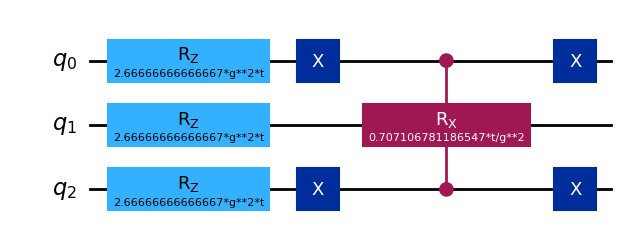

In [4]:
t = Parameter("t")
g = Parameter("g")

theta_E = (8 / 3) * g**2 * t
theta_B = 1 / (g**2 * np.sqrt(2)) * t

def one_step_new(n, N):
    qc = QuantumCircuit(n)
    
    for q in range(n):
        qc.rz(theta_E/N, q)

    for i in range(1, n - 1):       
        qc.x(i - 1)
        qc.x(i + 1)
        
        controlled_rx = RXGate(theta_B/N).control(2)  # 2 control qubits
        qc.append(controlled_rx, [i - 1, i + 1, i])

        qc.x(i - 1)
        qc.x(i + 1)
        
    return qc

def N_steps_compose_new(n, N):
    one_step_circuit = one_step_new(n, N)
    full_circuit = QuantumCircuit(n)
    for _ in range(N):
        full_circuit.compose(one_step_circuit, inplace=True)
    return full_circuit

n = 3
N = 1
circuit = N_steps_compose_new(n, N)
circuit.draw("mpl")

In [6]:
observables_labels = ["IZI", "ZZI", "IZZ", "ZIZ", "IXI", "XXI", "IXX", "XIX", "III"]
observables = [SparsePauliOp(label) for label in observables_labels]

In [8]:
def plot_measurement_loop(n, N, t=1.0):
    circuit = N_steps_compose_new(n, N)
    pm = generate_preset_pass_manager(optimization_level=1)
    isa_circuit = pm.run(circuit)
    mapped_observables = [
        observable.apply_layout(isa_circuit.layout) for observable in observables
    ]

    estimator = StatevectorEstimator()
    job = estimator.run([(isa_circuit, mapped_observables, [1.0, t])])
    
    result = job.result()
 
    pub_result = job.result()[0]

    values = pub_result.data.evs
    labels = observables_labels
    return labels, values

In [10]:
def plot_measurement_loop_one_observable(n, N, o_index, t=1.0):
    circuit = N_steps_compose_new(n, N)
    pm = generate_preset_pass_manager(optimization_level=1)
    isa_circuit = pm.run(circuit)
    mapped_observables = [
        observables[o_index].apply_layout(isa_circuit.layout)
    ]

    estimator = StatevectorEstimator()
    job = estimator.run([(isa_circuit, mapped_observables, [1.0, t])])
    
    result = job.result()
 
    pub_result = job.result()[0]

    values = pub_result.data.evs
    labels = N
    return labels, values

In [50]:
def exp_val_one_observable(N, n=3, o_index=1):
    exp_vals = []
    N_s = np.arange(1, N+1, 1)
    t_s = 1.0 / N_s
    for t, N in zip(t_s, N_s):
        exp_val = plot_measurement_loop_one_observable(n, N, o_index, t)[1][0]
        exp_vals.append(exp_val)

    plt.plot(N_s, exp_vals, "-o")
    plt.xlabel("N (where t * N = 1)")
    plt.ylabel(f"{observables_labels[o_index]} Expectation Value")
    plt.title(f"Expectation vs N for t*N=1, observable {observables_labels[o_index]}")
    plt.xticks(np.arange(1, N+1, 1))
    plt.grid(True)
    plt.show()

In [54]:
exp_val_one_observable(20)

03-Jul-25 11:16:35: Pass: ContainsInstruction - 0.01478 (ms)
03-Jul-25 11:16:35: Pass: InverseCancellation - 0.13995 (ms)
03-Jul-25 11:16:35: Pass: UnitarySynthesis - 0.01192 (ms)
03-Jul-25 11:16:35: Pass: UnrollCustomDefinitions - 0.03576 (ms)
03-Jul-25 11:16:35: Pass: BasisTranslator - 0.91505 (ms)
03-Jul-25 11:16:35: Pass: HighLevelSynthesis - 5.51295 (ms)
03-Jul-25 11:16:35: Pass: BasisTranslator - 0.02313 (ms)
03-Jul-25 11:16:35: Pass: Depth - 0.02098 (ms)
03-Jul-25 11:16:35: Pass: FixedPoint - 0.00787 (ms)
03-Jul-25 11:16:35: Pass: Size - 0.00477 (ms)
03-Jul-25 11:16:35: Pass: FixedPoint - 0.00501 (ms)
03-Jul-25 11:16:35: Pass: Optimize1qGatesDecomposition - 0.04625 (ms)
03-Jul-25 11:16:35: Pass: InverseCancellation - 0.08106 (ms)
03-Jul-25 11:16:35: Pass: GatesInBasis - 0.00405 (ms)
03-Jul-25 11:16:35: Pass: Depth - 0.00811 (ms)
03-Jul-25 11:16:35: Pass: FixedPoint - 0.00882 (ms)
03-Jul-25 11:16:35: Pass: Size - 0.00787 (ms)
03-Jul-25 11:16:35: Pass: FixedPoint - 0.00572 (ms)
03

In [98]:
# this one is wrong, because we are plotting on both ax1 and ax2 so the lines are messed up

# def exp_val_one_observable_dual_axis(N, n=3, o_index=1):
#     exp_vals = []
#     N_s = np.arange(1, N+1, 1)
#     t_s = 1.0 / N_s
#     for t, N in zip(t_s, N_s):
#         exp_val = plot_measurement_loop_one_observable(n, N, o_index, t)[1][0]
#         exp_vals.append(exp_val)

#     fig = plt.figure()
#     ax1 = fig.add_subplot(111)
#     ax2 = ax1.twiny()

#     ax1.plot(N_s, exp_vals, "o-")
#     ax1.set_xlabel("N")
#     ax1.set_ylabel(f"{observables_labels[o_index]} Expectation Value")
#     ax1.set_title(f"Expectation vs N (top axis: t = 1/N)")
#     ax1.grid(True)

#     ax2.plot(np.flip(t_s), exp_vals, "o-",color='purple')
#     ax2.set_xlabel("t = 1/N")
#     plt.show()

# exp_val_one_observable_dual_axis(20)

In [46]:
def exp_val_one_observable_dual_axis(N, o_index=1, n=3):
    exp_vals = []
    N_s = np.arange(1, N+1, 1)
    t_s = 1.0 / N_s
    for t, N in zip(t_s, N_s):
        exp_val = plot_measurement_loop_one_observable(n, N, o_index, t)[1][0]
        exp_vals.append(exp_val)

    fig = plt.figure(figsize=(12, 5))
    ax1 = fig.add_subplot(111)
    ax2 = ax1.twiny()

    ax1.plot(N_s, exp_vals, "o-")
    ax1.set_xlabel("N")
    ax1.set_ylabel(f"{observables_labels[o_index]} Expectation Value")
    ax1.set_xticks(np.arange(1, N+1, 1))
    ax1.set_title(f"Expectation vs N (top axis: t = 1/N)")
    ax1.grid(True)

    ax2.set_xlim(ax1.get_xlim())
    ax2.set_xticks(N_s)
    ax2.set_xticklabels(f"{t:.3f}" for t in t_s)
    ax2.tick_params(axis="x", labelrotation=45, pad=10)
    ax2.set_xlabel("t = 1 / N")

    plt.tight_layout()
    plt.show()

In [48]:
exp_val_one_observable_dual_axis(20)

03-Jul-25 11:13:17: Pass: ContainsInstruction - 0.02694 (ms)
03-Jul-25 11:13:17: Pass: InverseCancellation - 0.20313 (ms)
03-Jul-25 11:13:17: Pass: UnitarySynthesis - 0.02384 (ms)
03-Jul-25 11:13:17: Pass: UnrollCustomDefinitions - 0.11587 (ms)
03-Jul-25 11:13:17: Pass: BasisTranslator - 1.28412 (ms)
03-Jul-25 11:13:17: Pass: HighLevelSynthesis - 6.24514 (ms)
03-Jul-25 11:13:17: Pass: BasisTranslator - 0.01097 (ms)
03-Jul-25 11:13:17: Pass: Depth - 0.01478 (ms)
03-Jul-25 11:13:17: Pass: FixedPoint - 0.02098 (ms)
03-Jul-25 11:13:17: Pass: Size - 0.00596 (ms)
03-Jul-25 11:13:17: Pass: FixedPoint - 0.00715 (ms)
03-Jul-25 11:13:17: Pass: Optimize1qGatesDecomposition - 0.05889 (ms)
03-Jul-25 11:13:17: Pass: InverseCancellation - 0.08392 (ms)
03-Jul-25 11:13:17: Pass: GatesInBasis - 0.00691 (ms)
03-Jul-25 11:13:17: Pass: Depth - 0.00882 (ms)
03-Jul-25 11:13:17: Pass: FixedPoint - 0.00691 (ms)
03-Jul-25 11:13:17: Pass: Size - 0.00501 (ms)
03-Jul-25 11:13:17: Pass: FixedPoint - 0.00596 (ms)
03

In [63]:
for i in np.arange(4):
    exp_val_one_observable_dual_axis2(20, i)

In [60]:
def exp_val_tN_2(N, o_index=1, n=3):
    exp_vals = []
    N_s = np.arange(1, N+1, 1)
    t_s = 2.0 / N_s
    for t, N in zip(t_s, N_s):
        exp_val = plot_measurement_loop_one_observable(n, N, o_index, t)[1][0]
        exp_vals.append(exp_val)

    fig = plt.figure(figsize=(12, 5))
    ax1 = fig.add_subplot(111)
    ax2 = ax1.twiny()

    ax1.plot(N_s, exp_vals, "o-")
    ax1.set_xlabel("N")
    ax1.set_ylabel(f"{observables_labels[o_index]} Expectation Value")
    ax1.set_xticks(np.arange(1, N+1, 1))
    ax1.set_title(f"Expectation vs N (top axis: t = 1/N)")
    ax1.grid(True)

    ax2.set_xlim(ax1.get_xlim())
    ax2.set_xticks(N_s)
    ax2.set_xticklabels(f"{t:.3f}" for t in t_s)
    ax2.tick_params(axis="x", labelrotation=45, pad=10)
    ax2.set_xlabel("t = 1 / N")

    plt.tight_layout()
    plt.show()

In [36]:
exp_val_tN_2(40)

03-Jul-25 11:09:42: Pass: ContainsInstruction - 0.02885 (ms)
03-Jul-25 11:09:42: Pass: InverseCancellation - 0.26393 (ms)
03-Jul-25 11:09:42: Pass: UnitarySynthesis - 0.01884 (ms)
03-Jul-25 11:09:42: Pass: UnrollCustomDefinitions - 0.08392 (ms)
03-Jul-25 11:09:42: Pass: BasisTranslator - 0.91481 (ms)
03-Jul-25 11:09:42: Pass: HighLevelSynthesis - 6.76608 (ms)
03-Jul-25 11:09:42: Pass: BasisTranslator - 0.01383 (ms)
03-Jul-25 11:09:42: Pass: Depth - 0.01216 (ms)
03-Jul-25 11:09:42: Pass: FixedPoint - 0.01001 (ms)
03-Jul-25 11:09:42: Pass: Size - 0.00715 (ms)
03-Jul-25 11:09:42: Pass: FixedPoint - 0.00501 (ms)
03-Jul-25 11:09:42: Pass: Optimize1qGatesDecomposition - 0.05102 (ms)
03-Jul-25 11:09:42: Pass: InverseCancellation - 0.09894 (ms)
03-Jul-25 11:09:42: Pass: GatesInBasis - 0.00286 (ms)
03-Jul-25 11:09:42: Pass: Depth - 0.01097 (ms)
03-Jul-25 11:09:42: Pass: FixedPoint - 0.00501 (ms)
03-Jul-25 11:09:42: Pass: Size - 0.00405 (ms)
03-Jul-25 11:09:42: Pass: FixedPoint - 0.00882 (ms)
03

In [19]:
exp_val_tN_2(40, 8)

27-Jun-25 16:48:25: Pass: ContainsInstruction - 0.03290 (ms)
27-Jun-25 16:48:25: Pass: InverseCancellation - 0.26226 (ms)
27-Jun-25 16:48:25: Pass: UnitarySynthesis - 0.01669 (ms)
27-Jun-25 16:48:25: Pass: UnrollCustomDefinitions - 0.06294 (ms)
27-Jun-25 16:48:25: Pass: BasisTranslator - 1.14107 (ms)
27-Jun-25 16:48:25: Pass: HighLevelSynthesis - 7.20978 (ms)
27-Jun-25 16:48:25: Pass: BasisTranslator - 0.02408 (ms)
27-Jun-25 16:48:25: Pass: Depth - 0.00978 (ms)
27-Jun-25 16:48:25: Pass: FixedPoint - 0.00596 (ms)
27-Jun-25 16:48:25: Pass: Size - 0.00501 (ms)
27-Jun-25 16:48:25: Pass: FixedPoint - 0.00405 (ms)
27-Jun-25 16:48:25: Pass: Optimize1qGatesDecomposition - 0.03290 (ms)
27-Jun-25 16:48:25: Pass: InverseCancellation - 0.10824 (ms)
27-Jun-25 16:48:25: Pass: GatesInBasis - 0.00405 (ms)
27-Jun-25 16:48:25: Pass: Depth - 0.01597 (ms)
27-Jun-25 16:48:25: Pass: FixedPoint - 0.00596 (ms)
27-Jun-25 16:48:25: Pass: Size - 0.00811 (ms)
27-Jun-25 16:48:25: Pass: FixedPoint - 0.00715 (ms)
27

In [58]:
def exp_val_tN_3(N, o_index=1, n=3):
    exp_vals = []
    N_s = np.arange(1, N+1, 1)
    t_s = 3.0 / N_s
    for t, N in zip(t_s, N_s):
        exp_val = plot_measurement_loop_one_observable(n, N, o_index, t)[1][0]
        exp_vals.append(exp_val)

    fig = plt.figure(figsize=(12, 5))
    ax1 = fig.add_subplot(111)
    ax2 = ax1.twiny()

    ax1.plot(N_s, exp_vals, "o-")
    ax1.set_xlabel("N")
    ax1.set_ylabel(f"{observables_labels[o_index]} Expectation Value")
    ax1.set_xticks(np.arange(1, N+1, 1))
    ax1.set_title(f"Expectation vs N (top axis: t = 1/N)")
    ax1.grid(True)

    ax2.set_xlim(ax1.get_xlim())
    ax2.set_xticks(N_s)
    ax2.set_xticklabels(f"{t:.3f}" for t in t_s)
    ax2.tick_params(axis="x", labelrotation=45, pad=10)
    ax2.set_xlabel("t = 1 / N")
    
    plt.tight_layout()
    plt.show()

In [71]:
exp_val_tN_3(40)

In [56]:
def exp_val_given_T(T=1.0, N=40, o_index=1, n=3):
    exp_vals = []
    N_s = np.arange(1, N+1, 1)
    t_s = T / N_s
    for t, N in zip(t_s, N_s):
        exp_val = plot_measurement_loop_one_observable(n, N, o_index, t)[1][0]
        exp_vals.append(exp_val)

    fig = plt.figure(figsize=(12, 5))
    ax1 = fig.add_subplot(111)
    ax2 = ax1.twiny()

    ax1.plot(N_s, exp_vals, "o-")
    ax1.set_xlabel("N")
    ax1.set_ylabel(f"{observables_labels[o_index]} Expectation Value")
    ax1.set_xticks(np.arange(1, N+1, 1))
    ax1.set_title(f"Expectation vs N (top axis: t = 1/N)")
    ax1.grid(True)

    ax2.set_xlim(ax1.get_xlim())
    ax2.set_xticks(N_s)
    ax2.set_xticklabels(f"{t:.3f}" for t in t_s)
    ax2.tick_params(axis="x", labelrotation=45, pad=10)
    ax2.set_xlabel("t = 1 / N")

    plt.tight_layout()
    plt.show()

In [28]:
exp_val_given_T(3.0, 40)

03-Jul-25 11:08:47: Pass: ContainsInstruction - 0.02003 (ms)
03-Jul-25 11:08:47: Pass: InverseCancellation - 0.21887 (ms)
03-Jul-25 11:08:47: Pass: UnitarySynthesis - 0.01216 (ms)
03-Jul-25 11:08:47: Pass: UnrollCustomDefinitions - 0.04292 (ms)
03-Jul-25 11:08:47: Pass: BasisTranslator - 0.93579 (ms)
03-Jul-25 11:08:47: Pass: HighLevelSynthesis - 5.96905 (ms)
03-Jul-25 11:08:47: Pass: BasisTranslator - 0.02098 (ms)
03-Jul-25 11:08:47: Pass: Depth - 0.02098 (ms)
03-Jul-25 11:08:47: Pass: FixedPoint - 0.01311 (ms)
03-Jul-25 11:08:47: Pass: Size - 0.01001 (ms)
03-Jul-25 11:08:47: Pass: FixedPoint - 0.00787 (ms)
03-Jul-25 11:08:47: Pass: Optimize1qGatesDecomposition - 0.06127 (ms)
03-Jul-25 11:08:47: Pass: InverseCancellation - 0.13518 (ms)
03-Jul-25 11:08:47: Pass: GatesInBasis - 0.00310 (ms)
03-Jul-25 11:08:47: Pass: Depth - 0.01216 (ms)
03-Jul-25 11:08:47: Pass: FixedPoint - 0.00596 (ms)
03-Jul-25 11:08:47: Pass: Size - 0.00501 (ms)
03-Jul-25 11:08:47: Pass: FixedPoint - 0.00525 (ms)
03

In [91]:
exp_val_given_T(4.0, 40)

In [93]:
exp_val_given_T(5.0, 40)

In [22]:
def plot_multiple_T(T, o_index=1, N=40):
    fig = plt.figure(figsize=(12, 5))
    
    for T in np.arange(1.0, T+1.0, 1.0):
        exp_vals = []
        N = 40
        N_s = np.arange(1, N+1, 1)
        t_s = T / N_s
        for t, N in zip(t_s, N_s):
            exp_val = plot_measurement_loop_one_observable(3, N, o_index, t)[1][0]
            exp_vals.append(exp_val)
        # ax1 = fig.add_subplot(111)
        # ax2 = ax1.twiny()
    
        plt.plot(N_s, exp_vals, "o-", label=f"T = {T}")
        
        # ax2.set_xlim(ax1.get_xlim())
        # ax2.set_xticks(N_s)
        # ax2.set_xticklabels(f"{t:.3f}" for t in t_s)
        # ax2.tick_params(axis="x", labelrotation=45, pad=10)
        # ax2.set_xlabel("t = 1 / N")
    
    plt.xlabel("N")
    plt.ylabel(f"{observables_labels[o_index]} Expectation Value")
    plt.xticks(np.arange(1, N+1, 1))
    plt.title(f"Expectation vs N (top axis: t = 1/N)")
    plt.legend()
    plt.grid(True)
    
    plt.show()

In [ ]:
plot_multiple_T(5.0, 1)

03-Jul-25 11:20:40: Pass: ContainsInstruction - 0.00811 (ms)
03-Jul-25 11:20:40: Pass: InverseCancellation - 0.08988 (ms)
03-Jul-25 11:20:40: Pass: UnitarySynthesis - 0.00620 (ms)
03-Jul-25 11:20:40: Pass: UnrollCustomDefinitions - 0.02098 (ms)
03-Jul-25 11:20:40: Pass: BasisTranslator - 0.45228 (ms)
03-Jul-25 11:20:40: Pass: HighLevelSynthesis - 2.79617 (ms)
03-Jul-25 11:20:40: Pass: BasisTranslator - 0.01097 (ms)
03-Jul-25 11:20:40: Pass: Depth - 0.00834 (ms)
03-Jul-25 11:20:40: Pass: FixedPoint - 0.01502 (ms)
03-Jul-25 11:20:40: Pass: Size - 0.00405 (ms)
03-Jul-25 11:20:40: Pass: FixedPoint - 0.00596 (ms)
03-Jul-25 11:20:40: Pass: Optimize1qGatesDecomposition - 0.03099 (ms)
03-Jul-25 11:20:40: Pass: InverseCancellation - 0.05889 (ms)
03-Jul-25 11:20:40: Pass: GatesInBasis - 0.00310 (ms)
03-Jul-25 11:20:40: Pass: Depth - 0.00882 (ms)
03-Jul-25 11:20:40: Pass: FixedPoint - 0.00477 (ms)
03-Jul-25 11:20:40: Pass: Size - 0.00405 (ms)
03-Jul-25 11:20:40: Pass: FixedPoint - 0.00620 (ms)
03

In [97]:
plot_multiple_T(5.0, 1)
plot_multiple_T(10.0, 1)
plot_multiple_T(5.0, 2)
plot_multiple_T(5.0, 0)
plot_multiple_T(5.0, 3)

In [122]:
plot_multiple_T(5.0, 4) #"IXI"
plot_multiple_T(5.0, 5) #"XXI"
plot_multiple_T(5.0, 6) #"IXX"
plot_multiple_T(5.0, 7) #"XIX"

In [5]:
plot_multiple_T(5, 1)

NameError: name 'plt' is not defined